# Parcial Práctico · Colas de prioridad y Árbol de Expansión Mínima

**DDYA 2026-2** · Escuela Colombiana de Ingeniería Julio Garavito

**Estudiante:** Santiago Lugo Gómez · **Código:** 1000113097

Contexto:
Una empresa debe atender tareas técnicas según su prioridad y conectar seis dispositivos con la menor cantidad total de cable. En la primera parte se usa una Max-Priority Queue sobre un Max-Heap, y en la segunda, el algoritmo de Kruskal.

In [1]:
import math
import matplotlib.pyplot as plt

1) **Descripción del problema[1 pts]**

Una empresa debe atender tareas técnicas según su prioridad y conectar seis dispositivos con la menor cantidad total de cable. En la primera parte se usa una Max-Priority Queue sobre un Max-Heap y en la segunda, el algoritmo de Kruskal.

# 2) Requerimientos **[2 pts]**
**Requerimientos funcionales:**

1)Registrar las tareas con codigo, descripción y prioridad

2)Construir un Max Priority Queue sobre un Max Heap usando: BUILD-MAX-HEAP y MAX-HEAPIFY

3)Mostrar el arreglo inicial, el Max-Heap resultante y su árbol.

4)Insertar tareas nuevas sin romper la prioridad del Max-Heap

5)Registrar los dispositivos con nombre, ID y coordenadas y graficar donde quedan.

**Requerimientos no funcionales**
1) Restricción: no se usa heapq ni ninguna libreria que calcule el MST directamente.

2) Eficiencia: EXTRACT-MAX e insercion en O (logn). BUILD-MAX-HEAP en O(n) y Kruskal en O(m logn).

3) Entorno: Python 3, todo en un solo notebook entregado ya ejecutado.

4) Correctitud: despues de cada operación se revisa que se cumpla la propiedad del Max-heap. Para el MST se revisa que tenga 5 aristas, que no tenga ciclos y que el peso sea el minimo.

5) Legibilidad: nombres claros, resultados claros y con dos decimales.

## 3) Historias de usuario **[2 pts]**
1)Priorizar tareas: Como coordinador tecnico, quiero organizar las tareas en una cola de prioridad, para saber cual es la más urgente sin tener que revisar toda la lista.

Criterios de aceptación:
- La raiz del heap es T02, con prioridad 10.
- Ningun padre tiene menor prioridad que sus hijos.

2)Atender y agregar tareas: Como tecnico de soporte , quiero sacar la tarea más urgente y registrar tareas nuevas, para atender primero lo critico aunque llegue despues.

Criterios de aceptación:
- Las extracciones salen en orden: primero T02 y despues T04.
- T07, con prioridad 12, queda en la raiz, al insertarla.
3) Conocer las distancias: Como ingeniero de redes,quiero ver donde esta cada dispositivo y la distancia entre cada pareja, para saber cuanto cable costaria cada conexión posible.

Criterios de aceptación:
- Se graficaron los 6 dispositivos
- Se calcularon las 15 distancias con dos decimales.
## 4) Diagramas de flujo **[5 pts]**
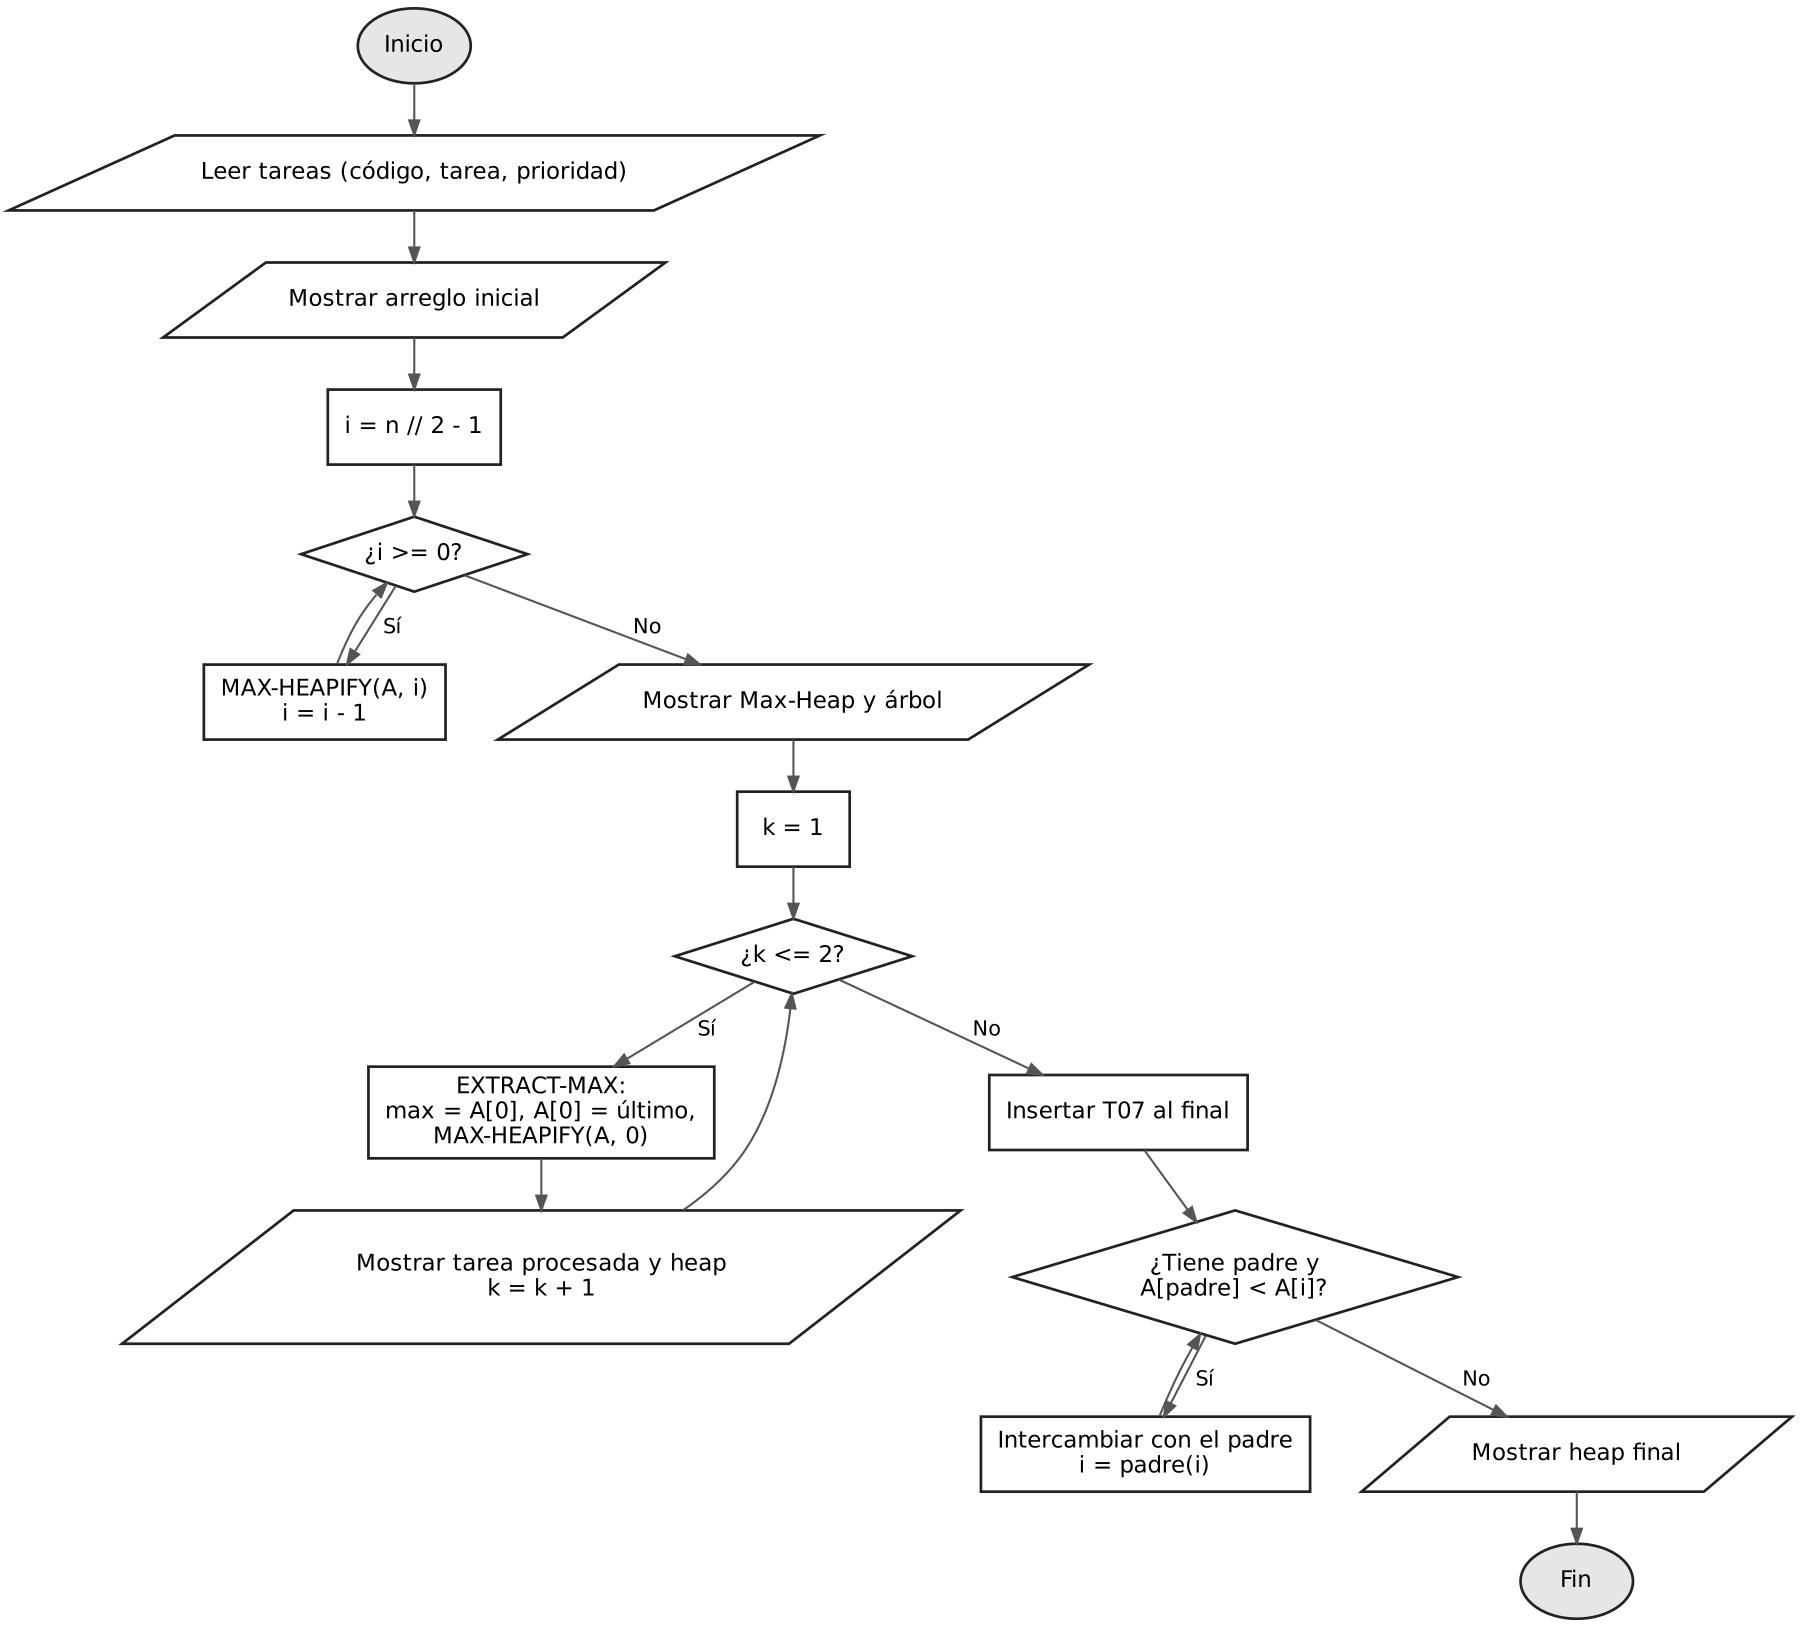
Descripción: Una empresa necesita atender sus tareas tecnicas en orden de urgencia y conectar seis dispositivos con la menor cantidad de cable posible. Para las tareas se implemento a mano una Max-Priority-Queu sobre un Max-heap,que siempre deja arriba la tarea de mayor prioridad y permite extraer e insertar en O(logn)

## **Punto 1. Cola de prioridad**

El heap se guarda en un arreglo indexado desde 0. Para el nodo en la posición [i]:

- padre: (i - 1) // 2
- hijo izquierdo: 2i + 1
- hijo derecho: 2i + 2

Cada elemento es una tupla (codigo, tarea, prioridad), y se compara por la prioridad.

- MAX-HEAPIFY(A, i):
supone que los subárboles de i ya son max-heaps. Si A[i] es menor que alguno de sus hijos, lo intercambia con el mayor y repite hacia abajo. Costo O(log n).
- BUILD-MAX-HEAP(A):
llama MAX-HEAPIFY desde el último nodo interno (n // 2 - 1) hasta la raíz. Costo O(n).

In [17]:
tareas = [
    ("T01", "Configurar servidor", 6),
    ("T02", "Reparar sensor", 10),
    ("T03", "Actualizar software", 4),
    ("T04", "Revisar cámara", 8),
    ("T05", "Generar respaldo", 3),
    ("T06", "Configurar alarma", 7),
]

def padre(i):
    return (i - 1) // 2

def izq(i):
    return 2 * i + 1

def der(i):
    return 2 * i + 2

def max_heapify(A, i, n):
    l, r = izq(i), der(i)
    mayor = i
    if l < n and A[l][2] > A[mayor][2]:
        mayor = l
    if r < n and A[r][2] > A[mayor][2]:
        mayor = r
    if mayor != i:
        A[i], A[mayor] = A[mayor], A[i]
        max_heapify(A, mayor, n)

def build_max_heap(A):
    for i in range(len(A) // 2 - 1, -1, -1):
        max_heapify(A, i, len(A))

def mostrar(A):
    for k, (cod, tarea, p) in enumerate(A):
        print(f"  [{k}] {cod}  {tarea:<38} prioridad {p}")

In [3]:
heap = list(tareas)
print("Arreglo inicial:")
mostrar(heap)

build_max_heap(heap)
print("\nMax-Heap resultante:")
mostrar(heap)
print("\nPrioridades:", [t[2] for t in heap])

Arreglo inicial:
  [0] T01  Configurar servidor                    prioridad 6
  [1] T02  Reparar sensor                         prioridad 10
  [2] T03  Actualizar software                    prioridad 4
  [3] T04  Revisar cámara                         prioridad 8
  [4] T05  Generar respaldo                       prioridad 3
  [5] T06  Configurar alarma                      prioridad 7

Max-Heap resultante:
  [0] T02  Reparar sensor                         prioridad 10
  [1] T04  Revisar cámara                         prioridad 8
  [2] T06  Configurar alarma                      prioridad 7
  [3] T01  Configurar servidor                    prioridad 6
  [4] T05  Generar respaldo                       prioridad 3
  [5] T03  Actualizar software                    prioridad 4

Prioridades: [10, 8, 7, 6, 3, 4]


**Árbol del heap.** Cada nodo muestra el código y la prioridad. Se verifica que todo padre tenga prioridad mayor o igual a la de sus hijos.

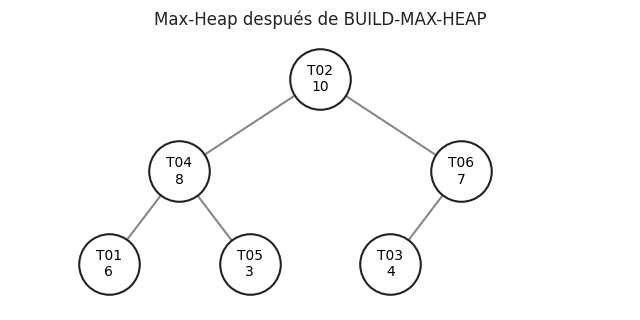

Cumple la propiedad de Max-Heap: True


In [4]:
def dibujar_heap(A, titulo):
    n = len(A)
    pos = {}
    for i in range(n):
        nivel = int(math.log2(i + 1))
        k = i - (2 ** nivel - 1)
        pos[i] = ((k + 0.5) / 2 ** nivel, -nivel)
    fig, ax = plt.subplots(figsize=(8, 3.6))
    for i in range(1, n):
        x1, y1 = pos[padre(i)]
        x2, y2 = pos[i]
        ax.plot([x1, x2], [y1, y2], color="#888888", lw=1.5, zorder=1)
    for i in range(n):
        x, y = pos[i]
        ax.scatter(x, y, s=1900, color="white", edgecolors="#222222", linewidths=1.5, zorder=2)
        ax.text(x, y, f"{A[i][0]}\n{A[i][2]}", ha="center", va="center", fontsize=10, zorder=3)
    ax.set_title(titulo, color="#222222")
    ax.set_xlim(-0.05, 1.05)
    ax.set_ylim(min(p[1] for p in pos.values()) - 0.5, 0.5)
    ax.axis("off")
    plt.show()

def es_max_heap(A):
    return all(A[padre(i)][2] >= A[i][2] for i in range(1, len(A)))

dibujar_heap(heap, "Max-Heap después de BUILD-MAX-HEAP")
print("Cumple la propiedad de Max-Heap:", es_max_heap(heap))

## Punto 2. Procesar tareas

- **EXTRACT-MAX:** guarda la raíz, pone el último elemento en la raíz, reduce el tamaño y llama MAX-HEAPIFY sobre la raíz. Costo O(log n).
- **MAX-HEAP-INSERT:** agrega el elemento al final y lo sube intercambiándolo con su padre mientras sea mayor (lo mismo que HEAP-INCREASE-KEY). Costo O(log n).

No se usa heapq.

In [6]:
def extract_max(A):
    if len(A) == 0:
        return None
    maximo = A[0]
    A[0] = A[-1]
    A.pop()
    max_heapify(A, 0, len(A))
    return maximo

def max_heap_insert(A, elemento):
    A.append(elemento)
    i = len(A) - 1
    while i > 0 and A[padre(i)][2] < A[i][2]:
        A[i], A[padre(i)] = A[padre(i)], A[i]
        i = padre(i)

In [7]:
for paso in range(1, 3):
    t = extract_max(heap)
    print(f"Extracción {paso}: se procesa {t[0]} - {t[1]} (prioridad {t[2]})")
    print("Heap resultante:")
    mostrar(heap)
    print("Cumple la propiedad de Max-Heap:", es_max_heap(heap), "\n")

Extracción 1: se procesa T02 - Reparar sensor (prioridad 10)
Heap resultante:
  [0] T04  Revisar cámara                         prioridad 8
  [1] T01  Configurar servidor                    prioridad 6
  [2] T06  Configurar alarma                      prioridad 7
  [3] T03  Actualizar software                    prioridad 4
  [4] T05  Generar respaldo                       prioridad 3
Cumple la propiedad de Max-Heap: True 

Extracción 2: se procesa T04 - Revisar cámara (prioridad 8)
Heap resultante:
  [0] T06  Configurar alarma                      prioridad 7
  [1] T01  Configurar servidor                    prioridad 6
  [2] T05  Generar respaldo                       prioridad 3
  [3] T03  Actualizar software                    prioridad 4
Cumple la propiedad de Max-Heap: True 



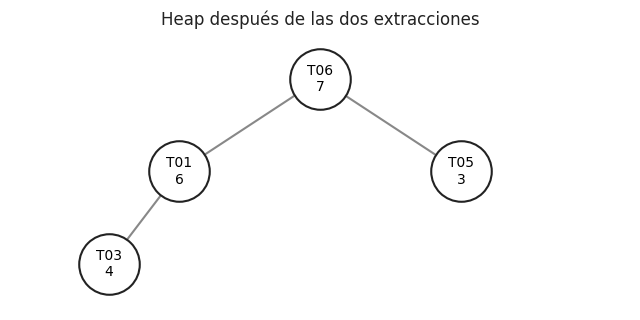

In [8]:
dibujar_heap(heap, "Heap después de las dos extracciones")

Heap después de insertar T07:
  [0] T07  Falla en sistema contra incendios      prioridad 12
  [1] T06  Configurar alarma                      prioridad 7
  [2] T05  Generar respaldo                       prioridad 3
  [3] T03  Actualizar software                    prioridad 4
  [4] T01  Configurar servidor                    prioridad 6
Cumple la propiedad de Max-Heap: True


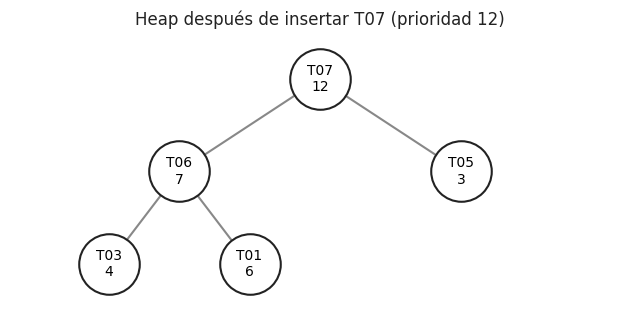

In [9]:
max_heap_insert(heap, ("T07", "Falla en sistema contra incendios", 12))
print("Heap después de insertar T07:")
mostrar(heap)
print("Cumple la propiedad de Max-Heap:", es_max_heap(heap))
dibujar_heap(heap, "Heap después de insertar T07 (prioridad 12)")

T07 entra al final del arreglo y sube hasta la raíz, porque su prioridad 12 es la mayor de todas.

## Punto 3. Dispositivos a conectar

Cada dispositivo es un vértice, y cada pareja de dispositivos forma una arista. Su peso es la distancia euclidiana:

$$d = \sqrt{(x_2 - x_1)^2 + (y_2 - y_1)^2}$$

Con 6 dispositivos hay 6 · 5 / 2 = 15 aristas.

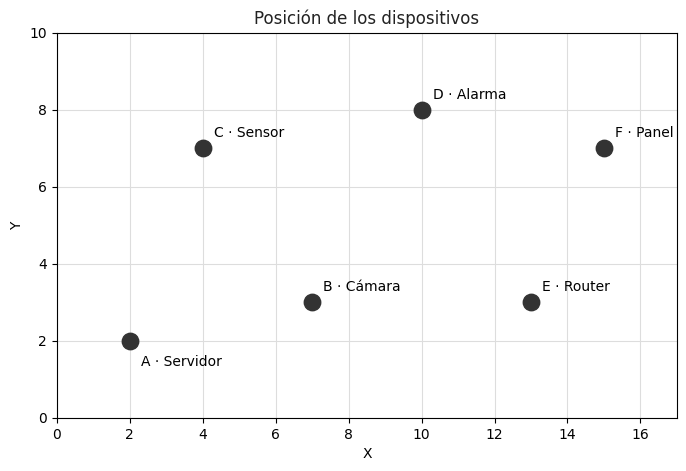

In [10]:
dispositivos = {
    "A": ("Servidor", 2, 2),
    "B": ("Cámara", 7, 3),
    "C": ("Sensor", 4, 7),
    "D": ("Alarma", 10, 8),
    "E": ("Router", 13, 3),
    "F": ("Panel", 15, 7),
}

fig, ax = plt.subplots(figsize=(8, 5))
for k, (nombre, x, y) in dispositivos.items():
    ax.scatter(x, y, s=140, color="#333333", zorder=3)
    ax.annotate(f"{k} · {nombre}", (x, y), textcoords="offset points", xytext=(8, -18) if k == "A" else (8, 8), fontsize=10)
ax.set_title("Posición de los dispositivos", color="#222222")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_xlim(0, 17)
ax.set_ylim(0, 10)
ax.grid(color="#dddddd")
plt.show()

In [11]:
def distancia(a, b):
    _, x1, y1 = dispositivos[a]
    _, x2, y2 = dispositivos[b]
    return math.sqrt((x2 - x1) ** 2 + (y2 - y1) ** 2)

ids = list(dispositivos)
aristas = []
for i in range(len(ids)):
    for j in range(i + 1, len(ids)):
        aristas.append((distancia(ids[i], ids[j]), ids[i], ids[j]))

print(f"Total de aristas: {len(aristas)}\n")
for d, a, b in aristas:
    print(f"  {a} - {b} : {d:.2f}")

Total de aristas: 15

  A - B : 5.10
  A - C : 5.39
  A - D : 10.00
  A - E : 11.05
  A - F : 13.93
  B - C : 5.00
  B - D : 5.83
  B - E : 6.00
  B - F : 8.94
  C - D : 6.08
  C - E : 9.85
  C - F : 11.00
  D - E : 5.83
  D - F : 5.10
  E - F : 4.47


In [12]:
print("Matriz de distancias:\n")
print("     " + "".join(f"{b:>8}" for b in ids))
for a in ids:
    print(f"  {a}  " + "".join(f"{distancia(a, b):>8.2f}" for b in ids))

Matriz de distancias:

            A       B       C       D       E       F
  A      0.00    5.10    5.39   10.00   11.05   13.93
  B      5.10    0.00    5.00    5.83    6.00    8.94
  C      5.39    5.00    0.00    6.08    9.85   11.00
  D     10.00    5.83    6.08    0.00    5.83    5.10
  E     11.05    6.00    9.85    5.83    0.00    4.47
  F     13.93    8.94   11.00    5.10    4.47    0.00


## Punto 4. Árbol de Expansión Mínima con Kruskal

1. Ordenar las aristas de menor a mayor peso.
2. Recorrerlas en ese orden y tomar una arista solo si une dos componentes distintas.
3. Para saber si una arista formaría ciclo se usa Union-Find: si los dos extremos ya tienen la misma raíz, la arista se descarta.
4. Detenerse cuando haya n − 1 = 5 conexiones.

**Complejidad.** Ordenar las m aristas cuesta O(m log m).

Con Union-Find (compresión de caminos y unión por rango), cada consulta es casi O(1).

 En total, O(m log m), y aquí m = 15. El MST se calcula a mano, sin funciones de librería.

In [13]:
def kruskal(vertices, aristas):
    padre_uf = {v: v for v in vertices}
    rango = {v: 0 for v in vertices}

    def buscar(x):
        if padre_uf[x] != x:
            padre_uf[x] = buscar(padre_uf[x])
        return padre_uf[x]

    def unir(a, b):
        ra, rb = buscar(a), buscar(b)
        if rango[ra] < rango[rb]:
            ra, rb = rb, ra
        padre_uf[rb] = ra
        if rango[ra] == rango[rb]:
            rango[ra] += 1

    ordenadas = sorted(aristas)
    mst = []
    print("Recorrido de Kruskal:\n")
    for d, a, b in ordenadas:
        if buscar(a) != buscar(b):
            unir(a, b)
            mst.append((a, b, d))
            print(f"  {a} - {b} : {d:.2f}  se agrega")
        else:
            print(f"  {a} - {b} : {d:.2f}  se descarta (formaría ciclo)")
        if len(mst) == len(vertices) - 1:
            break
    return mst

mst = kruskal(ids, aristas)

Recorrido de Kruskal:

  E - F : 4.47  se agrega
  B - C : 5.00  se agrega
  A - B : 5.10  se agrega
  D - F : 5.10  se agrega
  A - C : 5.39  se descarta (formaría ciclo)
  B - D : 5.83  se agrega


In [14]:
total = sum(d for _, _, d in mst)
print("Conexiones seleccionadas:\n")
for a, b, d in mst:
    print(f"  {a} - {b} : {d:.2f}")
print(f"\nLongitud total de cable: {total:.2f}")
print("Número de conexiones:", len(mst))

Conexiones seleccionadas:

  E - F : 4.47
  B - C : 5.00
  A - B : 5.10
  D - F : 5.10
  B - D : 5.83

Longitud total de cable: 25.50
Número de conexiones: 5


**Empate.** Las aristas B - D y D - E pesan lo mismo (√34 ≈ 5.83). Kruskal toma la primera en el orden, B - D. Si hubiera tomado D - E, el árbol sería otro, pero la longitud total sería la misma, 25.50. El MST no es único, pero su peso sí.

**Verificación.** Se prueban todos los subconjuntos de 5 aristas que conectan los 6 dispositivos (son 3003 subconjuntos de las 15 aristas) y se busca el de menor suma. Debe coincidir con lo que dio Kruskal.

In [15]:
from itertools import combinations

def conecta_todo(subconjunto):
    grupos = {v: {v} for v in ids}
    for _, a, b in subconjunto:
        if grupos[a] is grupos[b]:
            return False
        union = grupos[a] | grupos[b]
        for v in union:
            grupos[v] = union
    return True

mejor = min(sum(e[0] for e in s) for s in combinations(aristas, 5) if conecta_todo(s))
print(f"Mínimo por fuerza bruta: {mejor:.2f}")
print(f"Kruskal:                 {total:.2f}")
assert abs(mejor - total) < 1e-9
assert len(mst) == 5

Mínimo por fuerza bruta: 25.50
Kruskal:                 25.50


## Punto 5. Visualización final

La gráfica muestra los seis dispositivos, solo las conexiones del MST con su peso y, en el título, la longitud total de cable.

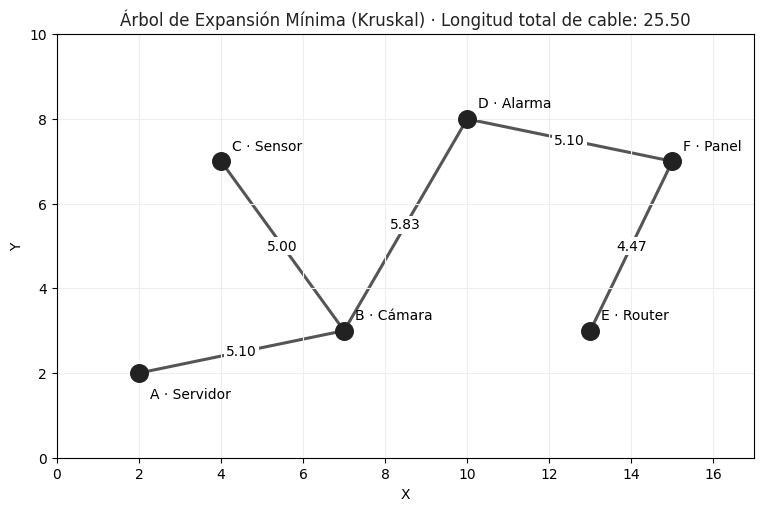

In [16]:
fig, ax = plt.subplots(figsize=(9, 5.5))
for a, b, d in mst:
    _, x1, y1 = dispositivos[a]
    _, x2, y2 = dispositivos[b]
    ax.plot([x1, x2], [y1, y2], color="#555555", lw=2.2, zorder=1)
    ax.text((x1 + x2) / 2, (y1 + y2) / 2, f"{d:.2f}", fontsize=10, ha="center", va="center",
            bbox=dict(facecolor="white", edgecolor="none", pad=1.5), zorder=2)
for k, (nombre, x, y) in dispositivos.items():
    ax.scatter(x, y, s=160, color="#222222", zorder=3)
    ax.annotate(f"{k} · {nombre}", (x, y), textcoords="offset points", xytext=(8, -18) if k == "A" else (8, 8), fontsize=10)
ax.set_title(f"Árbol de Expansión Mínima (Kruskal) · Longitud total de cable: {total:.2f}", color="#222222")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_xlim(0, 17)
ax.set_ylim(0, 10)
ax.grid(color="#eeeeee")
plt.show()